# 06 · Easy mode: `av_world.easy` and `av_world.compat`

The common jobs in one line each: simulate a city, write a driver in metres and seconds, score it, compare drivers, train with
PPO, save data. Then the bridges to the tools you already use: Gymnasium, PettingZoo, Stable-Baselines3, PyTorch, ONNX, pandas.
~5 minutes on a laptop CPU.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())
from av_world import easy, compat

av_world 0.4.0 in /home/user/av_world


## What is there

In [2]:
print("cities:", easy.cities())
for name, desc in list(easy.scenarios().items())[:10]:
    print(f"  {name:24s} {desc[:95]}")

cities: ['oakland', 'squirrel_hill', 'downtown', 'new_york', 'chicago', 'boston']
  jaywalker_misclassified  a pedestrian crosses outside the signal phase and the AV's perception drops out while it approa
  bus_dartout              a pedestrian steps out from in front of a stopped bus or van where cars cannot see
  stalled_vehicle_missed   a vehicle is stopped in the lane and the AV's sensor drops it from view while closing
  phantom_braking          the AV brakes hard for an obstacle that is not there while traffic follows
  sun_glare_blackout       the AV's sensors are blinded for a second or two at a time
  aggressive_cut_in        drivers squeeze into a gap far smaller than normal right in front of the AV
  red_light_runner         many drivers run the red and enter the junction at speed
  unprotected_left         drivers turn across oncoming traffic without looking
  cyclist_close_pass       many cyclists, and aggressive overtakers who clip them
  black_ice                the road

## 1. Simulate a city

Calibrated human drivers (their mistake rates match published crash statistics), 30 % AVs, 4 copies for 3 simulated minutes.
`summary()` is in plain units, with a 95 % interval on the crash rate (crashes are rare: short runs give wide intervals).

In [3]:
run = easy.simulate("oakland", minutes=3, av_share=0.3, copies=4)
print(run)
run.summary()

Run(oakland: 4 copies x 3.0 min, 48.0 vehicle-hours, 0 crashes, 21.2 km/h)


{'city': 'oakland',
 'copies': 4,
 'simulated_minutes_per_copy': 3.0,
 'vehicle_hours': 48.0,
 'av_hours': 13.3,
 'trips_finished': 212,
 'mean_speed_kmh': 21.2,
 'av_speed_kmh': 22.2,
 'crashes': 0,
 'crashes_per_1000_vehicle_hours': 0.0,
 'crashes_per_1000_vehicle_hours_95ci': [0.0, 76.81],
 'av_crashes': 0,
 'crashes_by_type': {},
 'red_light_runs': 1,
 'pedestrian_crossings': 3374,
 'av_share': 0.3,
 'scenario': None,
 'driver': 'rule-based'}

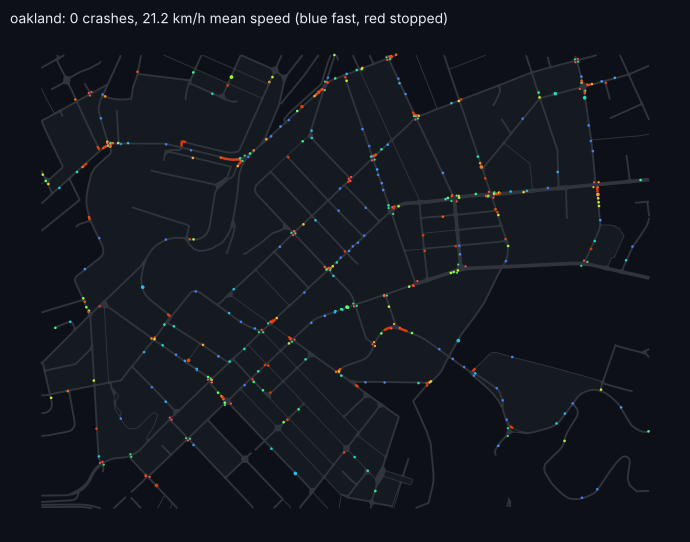

In [4]:
fig = run.show(); display(fig); plt.close(fig)

## 2. Write your own driver

A driver gets a `car` with named fields in plain units and returns an acceleration in m/s² (optionally also a junction caution).
Use `easy.jnp` (jax.numpy) inside, so the simulator can compile it and run it for every AV at once.

In [5]:
for k, unit in easy.Car.describe().items():
    print(f"  car.{k:24s} {unit}")

  car.speed                    m/s
  car.accel                    m/s^2
  car.speed_limit              m/s
  car.desired_speed            m/s
  car.lane_end                 m
  car.on_link                  True/False
  car.has_stop                 True/False
  car.stop_gap                 m
  car.has_lead                 True/False
  car.lead_gap                 m
  car.lead_speed               m/s
  car.closing_speed            m/s
  car.red                      True/False
  car.yellow                   True/False
  car.stop_sign                True/False
  car.must_yield               True/False
  car.junction_speed_cap       m/s
  car.gap_ok                   True/False
  car.room_after_junction      True/False
  car.crosswalk_busy           True/False
  car.time_to_conflict         s
  car.must_change_lane         True/False
  car.waiting                  s
  car.may_enter                True/False
  car.brake_needed_for_stop    m/s^2
  car.brake_needed_for_lead    m/s^2
  car.head

In [6]:
jnp = easy.jnp

@easy.driver
def two_second_rule(car):
    """Two seconds behind the car in front, a firm stop for every stop line (red light, stop sign, no gap), else the desired speed."""
    follow = jnp.where(car.has_lead & (car.lead_gap < 2 * car.speed + 4), -2 * car.brake_needed_for_lead - 1, 3.0)
    stop = jnp.where(car.has_stop & (car.stop_gap < 2 * car.speed + 8), -2 * car.brake_needed_for_stop - 1, 3.0)
    cruise = jnp.where(car.speed < car.desired_speed, 1.2, -0.5)
    return jnp.minimum(jnp.minimum(follow, stop), cruise)

icy = easy.simulate("oakland", minutes=3, av_share=0.3, copies=4, driver=two_second_rule, scenario="black_ice")
print(icy)

Run(oakland: 4 copies x 3.0 min, 44.3 vehicle-hours, 2 crashes, 16.4 km/h)


## 3. Score and compare on AVBench

The same warm states and random numbers as every leaderboard entry (~30 s per driver per scenario here). The leaderboard's
rule-based AV and best learned policy are added for reference without re-running them.

In [7]:
table = easy.compare({"two_second_rule": two_second_rule, "IDM (T = 1.5 s)": easy.drivers.idm()}, scenarios=["nominal"])

driver                                                             av_world_score  checks_passed  crashes_per_AV_hour  crashes_per_AV_hour_no_filter  comfort  progress_vs_humans  filter_share
two_second_rule                                                    43.4            5/8            0.0                  0.0                            0.744    0.687               0.151       
IDM (T = 1.5 s)                                                    81.0            6/8            0.0                  0.0                            0.85     0.955               0.002       
rule-based AV [leaderboard]                                        72.2            5/8            0.025                0.025                          0.904    1.061               0.0         
PPO + barrier teacher, speed + jaywalkers (phase 3) [leaderboard]  98.0            8/8            0.0                  0.0                            0.989    1.008               0.009       


Read the table: `crashes_per_AV_hour_no_filter` is what the driver does on its own, and `filter_share` how often the safety
filter had to step in. A first version of `two_second_rule` (it ignored stop lines and braked at most 3.5 m/s²) scored 0.2 with 28
crashes per AV-hour unaided: the filter was hiding it. This version is safe but cautious (slower than the humans), which the score
also shows.

## 4. Sweep one setting

`easy.sweep` runs `simulate` once per value. A miniature (4 copies x 2 min each), so the crash numbers are noisy: look at the
interval columns of `summary()` before reading anything into them; `examples/av_share_sweep.py` is the full version.

In [8]:
easy.sweep("av_share", [0.0, 0.5, 1.0], minutes=2, copies=4)

,av_share,vehicle_hours,crashes,crashes_per_1000_vehicle_hours,mean_speed_kmh,trips_finished,av_crashes
0,0.0,26.6,1,37.62,21.6,100,0
1,0.5,26.5,0,0.00,21.9,102,0
2,1.0,26.4,0,0.00,22.2,102,0


## 5. Train with PPO

`easy.train` fine-tunes the bundled policy (or starts from scratch) with any reward weights; ~2.5 s per update.

{'progress': 0.02, 'idle': 0.05, 'team': 0.01, 'comfort': 0.001, 'hard': 0.2, 'jerk': 4e-05, 'headway': 0.1, 'speed': 0.1, 'shield': 0.04, 'crash': -30.0, 'red': -20.0, 'near': -3.0}


results/easy/ppo_20261026_223804/policy.npz


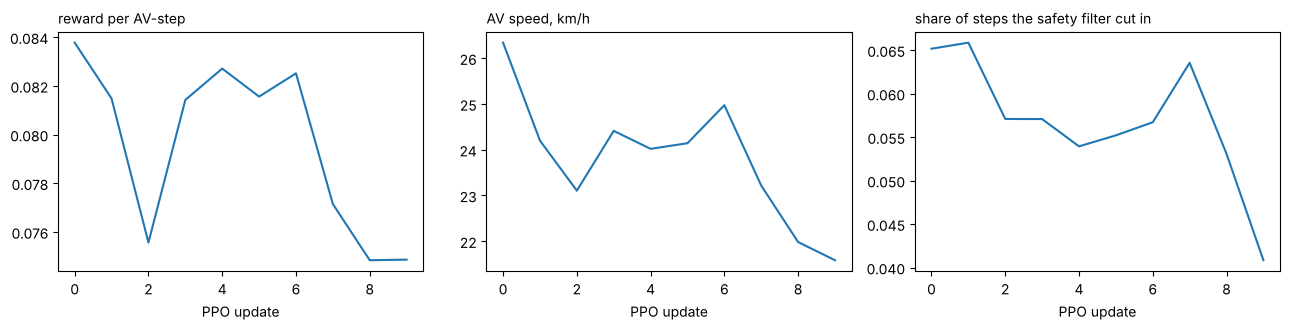

In [9]:
print({k: v for k, v in easy.reward_weights().items() if v})
policy = easy.train(updates=10, reward={"headway": 1.0}, quiet=True)
print(policy.path)
fig = policy.plot(); display(fig); plt.close(fig)

## 6. Save data in common formats

`run.save` continues the run while recording one copy: `.csv` / `.parquet` (one row per vehicle per step, metres, radians, m/s),
`.json` (the scene format of the CARLA replay and the OpenUSD export), `.xodr` (the roads as OpenDRIVE plus a CARLA replay script).

In [10]:
path = run.save("results/easy/oakland_trips.csv", seconds=20)
import pandas as pd
df = pd.read_csv(path)
print(df.shape); df.head()

(36231, 11)


,vehicle_id,kind,is_av,frame,t,x,y,yaw,speed,length,crashed_here
0,0,van,False,0,0.0,2494.48,196.12,2.549,2.32,7.00,False
1,1,car,False,0,0.0,3061.93,831.75,0.749,0.00,4.80,False
2,2,bus,False,0,0.0,2856.43,-307.58,-0.804,9.34,12.00,False
3,3,car,False,0,0.0,2769.50,287.95,-2.393,0.00,4.94,False
4,4,car,False,0,0.0,3131.55,729.12,-0.802,11.68,4.77,False


In [11]:
run.save("results/easy/oakland.xodr", seconds=10)
print(sorted(f for f in os.listdir("results/easy") if f.startswith("oakland")))

['oakland.json', 'oakland.xodr', 'oakland_replay.py', 'oakland_trips.csv']


## 7. Gymnasium: drive one AV yourself

`compat.GymEnv` is a standard `gymnasium.Env`: you control one AV (the ego) in the full city; the other AVs, humans and
pedestrians are the simulator. It passes Gymnasium's `check_env`.

In [12]:
env = compat.GymEnv("oakland", max_steps=200)
obs, info = env.reset(seed=0)
total, steps = 0.0, 0
while True:
    obs, reward, terminated, truncated, info = env.step(np.array([0.3, 0.0]))   # a gentle constant throttle
    total += reward; steps += 1
    if terminated or truncated:
        break
print(f"{steps} steps, return {total:.2f}, crashed: {info['crash']}")

200 steps, return 11.52, crashed: False


### Stable-Baselines3 on it, then the SB3 model drives every AV in the city

(`pip install stable-baselines3`; 2,048 steps here only show the plumbing, not a good driver.)

In [13]:
try:
    from stable_baselines3 import PPO
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "stable-baselines3"], check=True)
    from stable_baselines3 import PPO
t = time.time()
model = PPO("MlpPolicy", env, n_steps=512, batch_size=128, verbose=0, seed=0).learn(2048)
print(f"SB3 PPO: 2,048 steps in {time.time() - t:.0f} s")
print(easy.simulate("oakland", minutes=1, copies=1, driver=compat.from_sb3(model)))

SB3 PPO: 2,048 steps in 10 s


Run(oakland: 1 copies x 1.0 min, 2.6 vehicle-hours, 0 crashes, 23.2 km/h)


## 8. PyTorch and ONNX: take the trained policy anywhere

`compat.to_torch` rebuilds the JAX PPO policy as a `torch.nn.Sequential` (identical outputs); `compat.to_onnx` writes it for C++,
ROS or TensorRT; `compat.from_torch` puts any torch module back into the simulator as a driver.

In [14]:
import torch
net = compat.to_torch(av_world.data_path("policy.npz"))
from avrl import xppo as P
x = np.random.default_rng(0).normal(size=(8, 28)).astype(np.float32)
print(net)
print("max |torch - jax| =", float(np.abs(net(torch.from_numpy(x)).detach().numpy() - np.asarray(P.mean(P.load(av_world.data_path("policy.npz")), x))).max()))
print(easy.simulate("oakland", minutes=1, copies=1, driver=compat.from_torch(net)))

Sequential(
  (0): Linear(in_features=28, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=2, bias=True)
)


max |torch - jax| = 5.960464477539063e-08


Run(oakland: 1 copies x 1.0 min, 2.6 vehicle-hours, 0 crashes, 23.6 km/h)


## 9. PettingZoo: every AV an agent

`compat.ParallelEnv` follows the PettingZoo parallel API: agents (`"av_<slot>"`) appear when an AV trip starts and leave when it
ends or crashes.

In [15]:
par = compat.ParallelEnv("oakland", max_steps=100)
obs, infos = par.reset(seed=0)
print(len(par.agents), "agents at the start")
for _ in range(20):
    obs, rewards, terms, truncs, infos = par.step({a: np.array([0.2, 0.0]) for a in par.agents})
print(len(par.agents), "agents after 4 simulated seconds; mean reward", round(float(np.mean(list(rewards.values()))), 4))

26 agents at the start
26 agents after 4 simulated seconds; mean reward 0.0539


## What connects to what

| you have | use |
|---|---|
| a Gymnasium / SB3 / CleanRL agent | `compat.GymEnv`, then `compat.from_sb3(model)` in the full city |
| a multi-agent (PettingZoo / RLlib) setup | `compat.ParallelEnv` |
| a numpy or PyTorch policy | `compat.from_numpy(fn)`, `compat.from_torch(module)` |
| a C++ / ROS stack | `compat.to_onnx(...)`, or drive the simulator over TCP: [docs/SIL_HIL.md](../docs/SIL_HIL.md) |
| CARLA | `run.save("x.xodr")` (OpenDRIVE + a replay script) |
| NVIDIA Omniverse / Isaac | `easy.export_3d(...)` (OpenUSD) |
| a perception model (nuScenes-style data) | `easy.export_perception(...)` |
| pandas / Spark / SQL | `run.save("x.parquet")` |
| OpenStreetMap, Argoverse 2, Waymo maps and logs | `easy.simulate("map.osm")`, `xnet.avdata` ([docs/DATA_IMPORT.md](../docs/DATA_IMPORT.md)) |